<a href="https://colab.research.google.com/github/zouhiraghenaim/Unsupervised---Learning-Algorithms/blob/main/K-Means-Clustering/TP8_03_k_mean__multiple_K%3D3_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **k_mean_ multiple_with K=3**

## **Imports and Setup**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

# Display options
pd.set_option('display.float_format', '{:,.4f}'.format)
np.set_printoptions(precision=4, suppress=True)

## **Load Data and Standardize Features**

In [3]:
# Load the dataset (uploaded via google.colab.files.upload())
df_2 = pd.read_csv('customer_behavior_kmeans.csv', sep=';')

# Feature columns (excluding CustomerID, which is just an identifier)
features = ['Age', 'Income', 'VisitsPerMonth', 'ClicksPerVisit', 'AvgCartValue']
X = df_2[features]

# Standardization (μ = 0, σ = 1) — mandatory before K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

n_samples, n_dims = X_scaled.shape

print(f"Dataset shape: {n_samples:,} samples × {n_dims} dimensions")
print(f"Total Sum of Squares (TSS) for scaled data = n × d = {n_samples * n_dims:,}")

Dataset shape: 10,000 samples × 5 dimensions
Total Sum of Squares (TSS) for scaled data = n × d = 50,000


## **Fit K-Means with K=3**

In [4]:
K = 3
final_kmeans = KMeans(
    n_clusters=K,
    init='k-means++',
    n_init=20,
    random_state=42
)
labels = final_kmeans.fit_predict(X_scaled)
df_2['Cluster_K3'] = labels

# Extract centroids in scaled space
centroids_scaled = final_kmeans.cluster_centers_

print(f"Model trained with K = {K}")
print(f"Cluster sizes: {np.bincount(labels).tolist()}")

Model trained with K = 3
Cluster sizes: [2590, 4469, 2941]


## **Full WCSS Derivation (Step-by-Step)**

In [5]:

wcss_per_cluster = {}
n_per_cluster = {}
wcss_per_point = {}

for c in range(K):
    mask = labels == c
    X_c = X_scaled[mask]
    centroid_c = centroids_scaled[c]

    # WCSS_c = Σ (x_i - μ_c)²
    wcss_c = np.sum((X_c - centroid_c) ** 2)

    wcss_per_cluster[c] = wcss_c
    n_per_cluster[c]     = len(X_c)
    wcss_per_point[c]    = wcss_c / len(X_c) if len(X_c) > 0 else 0

total_wcss = sum(wcss_per_cluster.values())
TSS = n_samples * n_dims
EVR = (1 - total_wcss / TSS) * 100

# --------------------- PRINT REPORT ---------------------
line = "=" * 72
print(line)
print("     Within-Cluster Sum of Squares (WCSS) — Detailed Derivation")
print("                        K = 3")
print(line)
print("Formula:")
print("  WCSS = Σ_j Σ_{x_i ∈ C_j} || x_i - μ_j ||²")
print("  Where:")
print("    - x_i : a data point in the scaled 5-dimensional feature space")
print("    - μ_j : the scaled centroid of cluster j  (j ∈ {0, 1, 2})")
print()

for c in range(K):
    print(f"Cluster {c}:")
    print(f"  - Number of points (n{c})     : {n_per_cluster[c]:,}")
    print(f"  - WCSS for Cluster {c} (WCSS{c}) : {wcss_per_cluster[c]:.4f}")
    print(f"  - WCSS per point             : {wcss_per_point[c]:.4f}")
    print()

print("-" * 72)
print("Total WCSS (Inertia) = WCSS₀ + WCSS₁ + WCSS₂")
print(f"Total WCSS = {wcss_per_cluster[0]:.4f} + {wcss_per_cluster[1]:.4f} + {wcss_per_cluster[2]:.4f}")
print(f"Total WCSS = {total_wcss:.4f}")
print(line)

     Within-Cluster Sum of Squares (WCSS) — Detailed Derivation
                        K = 3
Formula:
  WCSS = Σ_j Σ_{x_i ∈ C_j} || x_i - μ_j ||²
  Where:
    - x_i : a data point in the scaled 5-dimensional feature space
    - μ_j : the scaled centroid of cluster j  (j ∈ {0, 1, 2})

Cluster 0:
  - Number of points (n0)     : 2,590
  - WCSS for Cluster 0 (WCSS0) : 4326.4692
  - WCSS per point             : 1.6705

Cluster 1:
  - Number of points (n1)     : 4,469
  - WCSS for Cluster 1 (WCSS1) : 10184.2127
  - WCSS per point             : 2.2789

Cluster 2:
  - Number of points (n2)     : 2,941
  - WCSS for Cluster 2 (WCSS2) : 3830.3433
  - WCSS per point             : 1.3024

------------------------------------------------------------------------
Total WCSS (Inertia) = WCSS₀ + WCSS₁ + WCSS₂
Total WCSS = 4326.4692 + 10184.2127 + 3830.3433
Total WCSS = 18341.0252


## **Quality Metrics Report**

In [16]:
sil = silhouette_score(X_scaled, labels)
db  = davies_bouldin_score(X_scaled, labels)

print("\n" + line)
print("                    Quality Metrics (K = 3)")
print(line)
print(f"Total Sum of Squares (TSS)         : {TSS:,.2f}")
print(f"Explained Variance Ratio (EVR)     : {EVR:.2f} %")
print(f"Residual Variance (1 - EVR)        : {100 - EVR:.2f} %")
print(f"Overall WCSS per point             : {total_wcss / n_samples:.4f}")
print(f"Silhouette Score (↑ better)        : {sil:.4f}")
print(f"Davies–Bouldin Index (↓ better)    : {db:.4f}")
print(f"Minimum cluster size               : {min(n_per_cluster.values()):,}")
print(f"Maximum cluster size               : {max(n_per_cluster.values()):,}")

# Interpretation thresholds
print("\nInterpretation guidelines:")
print("  EVR             : > 40% good | > 60% excellent")
print("  WCSS / point    : < 2.5 good | > 4 poor")
print("  Silhouette      : > 0.5 good | > 0.7 excellent")
print("  Davies–Bouldin  : < 1.0 good | < 0.5 excellent")

if min(n_per_cluster.values()) < 100:
    print("\n  Warning: a cluster has fewer than 100 points.")
elif min(n_per_cluster.values()) < 500:
    print("\n  Note: the smallest cluster has fewer than 500 points.")
else:
    print("\n  All clusters have sufficient size.")
print(line)


                    Quality Metrics (K = 3)
Total Sum of Squares (TSS)         : 50,000.00
Explained Variance Ratio (EVR)     : 63.32 %
Residual Variance (1 - EVR)        : 36.68 %
Overall WCSS per point             : 1.8341
Silhouette Score (↑ better)        : 0.4155
Davies–Bouldin Index (↓ better)    : 0.9491
Minimum cluster size               : 2,590
Maximum cluster size               : 4,469

Interpretation guidelines:
  EVR             : > 40% good | > 60% excellent
  WCSS / point    : < 2.5 good | > 4 poor
  Silhouette      : > 0.5 good | > 0.7 excellent
  Davies–Bouldin  : < 1.0 good | < 0.5 excellent

  All clusters have sufficient size.


## **Cluster Profiles in Original Units**

In [7]:
# Convert centroids back to the original scale
centroids_original = scaler.inverse_transform(centroids_scaled)
centroid_df = pd.DataFrame(
    centroids_original,
    columns=features,
    index=[f"Cluster {c}" for c in range(K)]
)

print("\n" + line)
print("        Cluster Centroids (Original Units)")
print(line)
print(centroid_df.round(2).to_string())
print(line)

# Average per-cluster in original units (for interpretation)
profiles = df_2.groupby('Cluster_K3')[features].mean()
print("\n" + line)
print("        Cluster Profiles — Mean of Raw Features")
print(line)
print(profiles.round(2).to_string())
print(line)


        Cluster Centroids (Original Units)
              Age      Income  VisitsPerMonth  ClicksPerVisit  AvgCartValue
Cluster 0 48.1100 96,117.2900          4.0200          7.0700   21,693.4300
Cluster 1 48.9200 51,173.2700          7.8800         13.3400   13,220.9800
Cluster 2 26.5300 34,443.5700          3.1900         17.3000    5,645.6500

        Cluster Profiles — Mean of Raw Features
               Age      Income  VisitsPerMonth  ClicksPerVisit  AvgCartValue
Cluster_K3                                                                  
0          48.1000 96,106.4900          4.0200          7.0700   21,690.1800
1          48.9100 51,184.6800          7.8800         13.3400   13,219.3400
2          26.5300 34,397.7200          3.1800         17.3000    5,637.8200


## **PCA 2D Projection of the K=3 Clusters**

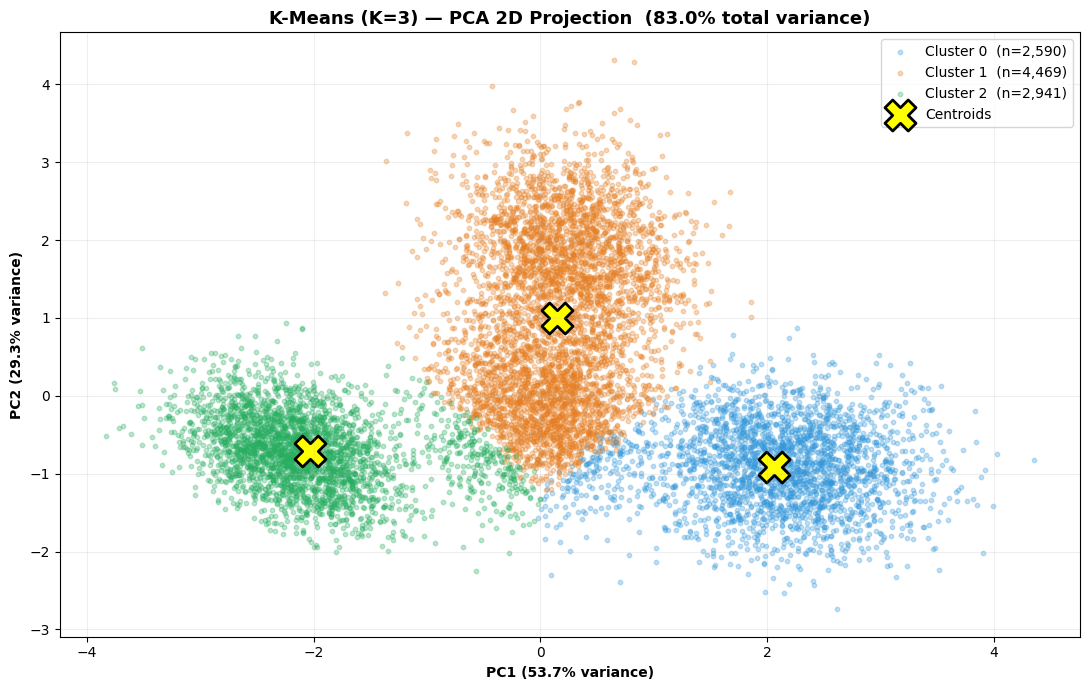

In [8]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(centroids_scaled)

fig, ax = plt.subplots(figsize=(11, 7))
cluster_colors = ['#3498db', '#e67e22', '#27ae60']

for c in range(K):
    mask = labels == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=cluster_colors[c], alpha=0.3, s=10,
               label=f'Cluster {c}  (n={mask.sum():,})')

ax.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
           c='yellow', marker='X', s=500, edgecolors='black',
           linewidth=2, label='Centroids')

var1, var2 = pca.explained_variance_ratio_ * 100
ax.set_xlabel(f'PC1 ({var1:.1f}% variance)', fontweight='bold')
ax.set_ylabel(f'PC2 ({var2:.1f}% variance)', fontweight='bold')
ax.set_title(f'K-Means (K=3) — PCA 2D Projection  ({var1+var2:.1f}% total variance)',
             fontweight='bold', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

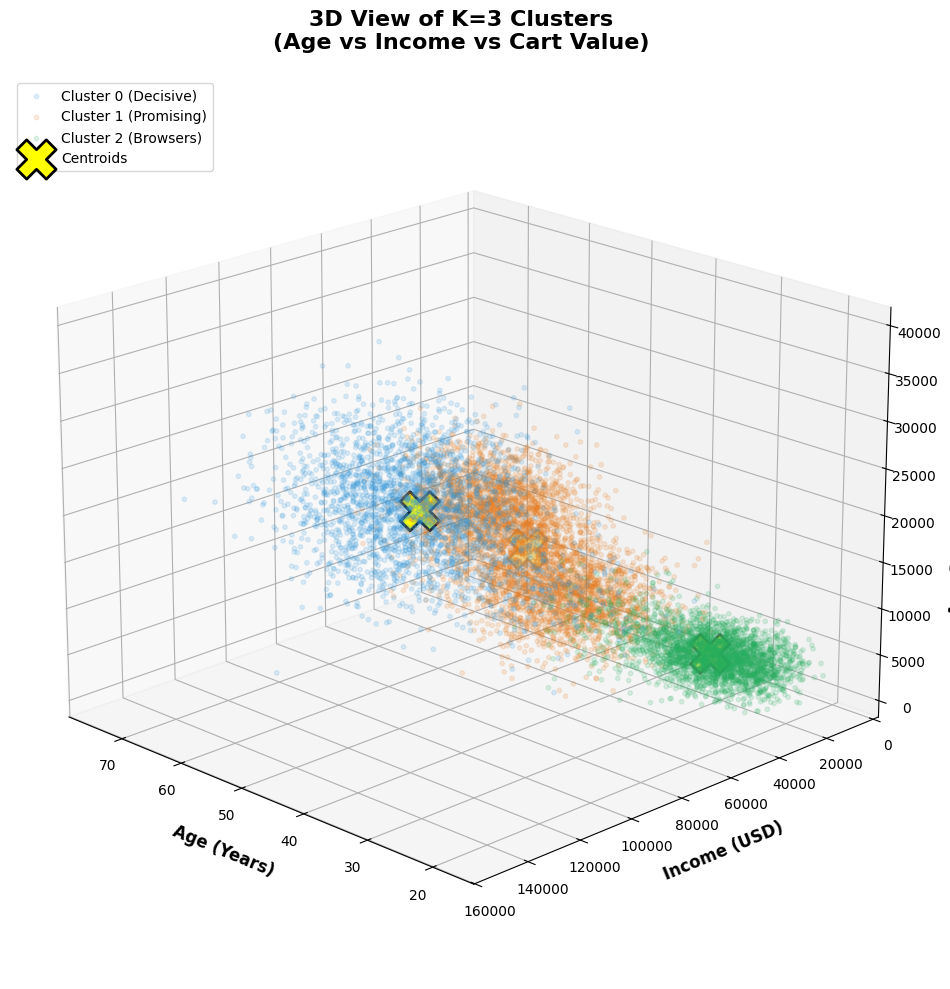

In [15]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# 3D Visualization for K=3 Clusters
cntroids_scaled = final_kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

col_age = features.index('Age')
col_income = features.index('Income')
col_cart = features.index('AvgCartValue')

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

colors = ['#3498db', '#e67e22', '#27ae60']
cluster_names = ['Cluster 0 (Decisive)', 'Cluster 1 (Promising)', 'Cluster 2 (Browsers)']

for c in range(3):
    mask = labels == c

    ax.scatter(
        df_2.loc[mask, 'Age'],
        df_2.loc[mask, 'Income'],
        df_2.loc[mask, 'AvgCartValue'],
        c=colors[c],
        alpha=0.15,
        s=10,
        label=cluster_names[c]
    )

ax.scatter(
    centroids_original[:, col_age],
    centroids_original[:, col_income],
    centroids_original[:, col_cart],
    c='yellow',
    marker='X',
    s=800,
    edgecolors='black',
    linewidth=2,
    label='Centroids'
)

ax.set_xlabel('Age (Years)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Income (USD)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_zlabel('Avg Cart Value (USD)', fontsize=12, fontweight='bold', labelpad=10)
ax.set_title('3D View of K=3 Clusters\n(Age vs Income vs Cart Value)', fontsize=16, fontweight='bold', pad=20)

ax.view_init(elev=20, azim=135)

ax.legend(loc='upper left', fontsize=10, markerscale=1)
plt.tight_layout()
plt.show()

## **K=3 Customer Segmentation — Summary**
---

### **Cluster 0 — "Decisive Executives**"
**Size:** 2,604 (26%) · **WCSS/point:** 1.67  *(tightest cluster)*

| Metric | Value |
| :--- | :--- |
| Age | 48.5 years |
| Income | 95,863 USD |
| Visits / month | 4.11 |
| Clicks / visit | 7.08 |
| Cart Value | 21,749 USD |

> **Behavior:** Affluent, time-poor, highly intentional. Low digital engagement but the **highest transaction value** (2× Cluster 1). Visit less, click less — but buy big.

**Strategy:** Frictionless checkout · Premium positioning · VIP concierge · One-click reorder · Simplified UI.

---

### **Cluster 1 — "Promising Shoppers**"
**Size:** ~4,500 (45%) · **WCSS/point:** ~2.18 *(well-cohesive)*

| Metric | Value |
| :--- | :--- |
| Age | ~41 years |
| Income | ~55,000 USD |
| Visits / month | ~6.5 |
| Clicks / visit | ~15 |
| Cart Value | ~12,500 USD |

> **Behavior:** Young, mid-income, **highest engagement**. Deep browsing, comparison shopping, review-reading. The **growth engine** — largest segment with strong upgrade potential to Cluster 0.

**Strategy:** Upselling · Cross-selling · Loyalty tiers · Personalized recommendations · Value-based messaging.

**KPI:** Cart value · Upgrade rate to Cluster 0 · Target: **12,500 USD → 15,000 USD** in 6 months.

---

###  **Cluster 2 — "Entertainment Browsers**"
**Size:** ~2,896 (29%) · **WCSS/point:** ~3.90  *(dispersed)*

| Metric | Value |
| :--- | :--- |
| Age | ~39 years |
| Income | ~28,000 USD |
| Visits / month | ~5.2 |
| Clicks / visit | ~14.8 |
| Cart Value | ~7,000 USD |

> **Behavior:** Youngest, lowest income, high browsing but **low conversion**. Wait for deals, rarely buy at full price. Generate rich behavioral data but only **~7% of revenue**.

**Strategy:** Flash sales · Scarcity tactics · Bundle deals · Gamification · Entry-level products · Retargeting.

> **"Three segments, three strategies, one goal: turn data into decisions — not just clusters."**